In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-bar-chart

**Figure 1: Accuracy of four training methods on GSM8K, MATH and HumanEval.** Ours is the most accurate on every benchmark, ahead of the strongest baseline, DPO, by 0.029 to 0.043 (e.g. 0.842 vs. 0.806 on GSM8K).

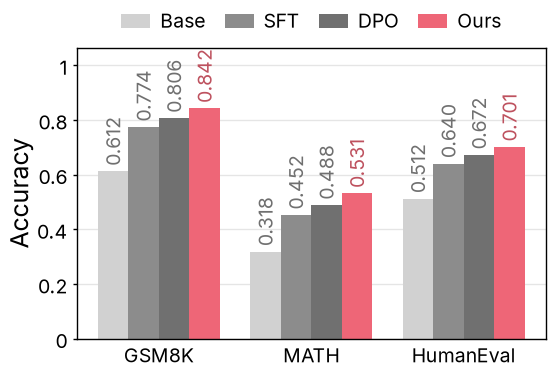

In [2]:
with open("../data/grouped-bar-chart.json") as f:
    data = json.load(f)
benchmarks = data["benchmarks"]
methods = ["Base", "SFT", "DPO", "Ours"]
method_colors = {
    "Base": lighten(colors["neutral"]),
    "SFT": colors["neutral"],
    "DPO": darken(colors["neutral"]),
    "Ours": colors["ours"],
}

fig, ax = plt.subplots(figsize=(2.75, 2))
x = np.arange(len(benchmarks))
width = 0.8 / len(methods)
for i, method in enumerate(methods):
    color = method_colors[method]
    bars = ax.bar(x + (i - (len(methods) - 1) / 2) * width, data["scores"][method], width,
                  color=color, linewidth=0, label=method)
    label_color = colors["ours"] if method == "Ours" else colors["neutral"]
    ax.bar_label(bars, fmt="%#.3g", rotation=90, padding=2, color=darken(label_color))

ax.set_xticks(x, labels=benchmarks)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_ylabel("Accuracy")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=4, frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/grouped-bar-chart.pdf")
fig.savefig("../outputs/grouped-bar-chart.png")
plt.show()